# Lab 3 (Parcial 2) · Parte I — Tarea de copia con retardo: RNN frente a LSTM

## Objetivo

Entender exactamente qué hace el código proporcionado (`Lab3_CopyDelayTaskCV.ipynb`): **cuál es la tarea, cómo se calcula el error y por qué tiene sentido usarla**. Después, ejecutarlo con distintos parámetros para sacar conclusiones sobre las diferencias entre una **RNN *vanilla*** y una **LSTM**.

El enunciado avisa de que, con la configuración por defecto, los dos modelos se comportan de forma parecida e **incluso peor la LSTM**. La tarea es **mirar las curvas de aprendizaje, optimizar los parámetros y hacer una comparación justa** de los dos modelos.

Plan:

1. El código, explicado: la tarea, el error, por qué tiene sentido; y su ejecución tal cual.
2. Diagnóstico con las curvas de aprendizaje: por qué la LSTM sale peor.
3. Experimentos: presupuesto de entrenamiento, tamaño oculto, inicialización que conserva la memoria y tasa de aprendizaje.
4. Comparación justa final (mismo presupuesto, cada modelo con sus mejores parámetros y también con el mismo número de parámetros).
5. Qué posiciones recuerda cada modelo.
6. Conclusiones.

## 0. Preparación del entorno

**Dispositivo.** El código original usa CUDA si existe y si no, la CPU; la sección 1 se ejecuta así. Para los experimentos, cada modelo se entrena donde es más rápido en un Mac con chip M3: la **LSTM en la GPU (MPS)**, que tiene un núcleo optimizado para ella (unas 2 veces más rápida que en CPU con 128 unidades), y la **RNN en la CPU** (en MPS sería más lenta: la red es tan pequeña que domina el coste de lanzar cada operación).

In [1]:
%matplotlib inline
import copy
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

LAB_DIR = Path.cwd()
for candidato in (Path.cwd(), Path.cwd() / 'lab3', Path.cwd() / 'Parcial-2' / 'Lab3-LSTM' / 'lab3'):
    if (candidato / 'data').exists():
        LAB_DIR = candidato
        break
MPS = torch.backends.mps.is_available()
DISPOSITIVO = {'RNN': torch.device('cpu'), 'LSTM': torch.device('mps') if MPS else torch.device('cpu')}
torch.set_num_threads(min(4, os.cpu_count()))
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.precision', 3)
print('PyTorch', torch.__version__, '| dispositivos de los experimentos:', {k: str(v) for k, v in DISPOSITIVO.items()})

PyTorch 2.15.0 | dispositivos de los experimentos: {'RNN': 'cpu', 'LSTM': 'mps'}


# 1. El código proporcionado

## 1.1. La tarea: copiar con retardo

Cada ejemplo es una secuencia de longitud $2d$, donde $d$ es el **retardo** (*delay*):

* en los **$d$ primeros pasos** la entrada es un vector de **5 bits aleatorios** (0 o 1 con probabilidad ½, independientes);
* en los **$d$ últimos pasos** la entrada es **cero**;
* el **objetivo** es cero en la primera mitad y, en la segunda, **la misma secuencia de vectores de la primera mitad**: en el paso $d+k$ la red debe reproducir el vector que vio en el paso $k$.

Es decir, la salida es la entrada **retrasada $d$ pasos**: $\mathbf y_t = \mathbf x_{t-d}$. La red es un «eco» o línea de retardo.

Retardo d = 4, longitud 2d = 8. Filas = pasos de tiempo, columnas = los 5 bits.
  entrada x             objetivo y            
          0  1  2  3  4          0  1  2  3  4
t                                             
0         0  1  0  0  0          0  0  0  0  0
1         1  0  1  0  1          0  0  0  0  0
2         0  0  0  0  0          0  0  0  0  0
3         1  1  1  0  0          0  0  0  0  0
4         0  0  0  0  0          0  1  0  0  0
5         0  0  0  0  0          1  0  1  0  1
6         0  0  0  0  0          0  0  0  0  0
7         0  0  0  0  0          1  1  1  0  0


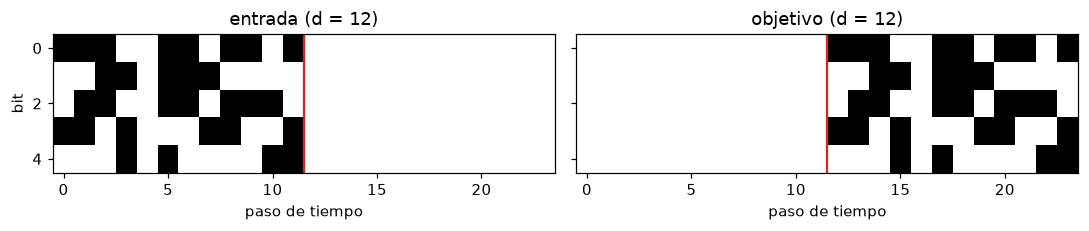

In [2]:
input_size = 5
device = 'cuda' if torch.cuda.is_available() else 'cpu'

def generate_batch_delay(batch_size, delay, input_size):
    seq_len = delay * 2
    seq = torch.zeros(batch_size, seq_len, input_size)
    seq[:, :delay, :] = (torch.rand(batch_size, delay, input_size) > 0.5).float()   # bits aleatorios
    target = torch.zeros_like(seq)
    target[:, delay:, :] = seq[:, :delay, :]                                         # la misma secuencia, d pasos después
    return seq.to(device), target.to(device), seq_len

torch.manual_seed(0)
x, y, T = generate_batch_delay(1, 4, input_size)
print('Retardo d = 4, longitud 2d = 8. Filas = pasos de tiempo, columnas = los 5 bits.')
print(pd.concat({'entrada x': pd.DataFrame(x[0].int().cpu().numpy()), 'objetivo y': pd.DataFrame(y[0].int().cpu().numpy())},
                axis=1).rename_axis('t').to_string())

torch.manual_seed(1)
x, y, T = generate_batch_delay(1, 12, input_size)
fig, ax = plt.subplots(1, 2, figsize=(10, 2.2), sharey=True)
for a, m, t in ((ax[0], x, 'entrada'), (ax[1], y, 'objetivo')):
    a.imshow(m[0].cpu().T, cmap='Greys', aspect='auto', vmin=0, vmax=1); a.set_title(f'{t} (d = 12)'); a.set_xlabel('paso de tiempo')
    a.axvline(11.5, color='tab:red', lw=1.5); a.grid(False)
ax[0].set_ylabel('bit'); plt.tight_layout(); plt.show()

## 1.2. Cómo se calcula el error y la exactitud

* La red da en cada paso 5 números (*logits*), uno por bit.
* La pérdida es **`BCEWithLogitsLoss`** (sigmoide + entropía cruzada binaria) **solo sobre la segunda mitad** (`output[:, delay:, :]`): lo que la red emita en la primera mitad no importa, porque ahí todavía no hay nada que recordar.
* La **exactitud** es la proporción de **bits** acertados en la segunda mitad, con umbral 0,5 sobre la sigmoide. Un modelo sin memoria no puede hacer nada mejor que acertar al azar: **50 %**. La pérdida correspondiente es $\ln 2\approx0{,}693$.

Para entrenar se generan **datos nuevos en cada lote** (100 lotes de 32 secuencias por «época»), así que nunca se repite un ejemplo: **no puede haber sobreajuste**. La validación (20 lotes nuevos) solo sirve para la parada temprana (paciencia 3) y la evaluación final son otros 20 lotes.

## 1.3. Por qué tiene sentido esta tarea

* **Aísla la memoria.** Los bits son aleatorios e independientes: no hay ningún patrón que aprender salvo **recordar**. Todo lo que supere el 50 % es memoria pura.
* **Controla exactamente la distancia de la dependencia.** Cada salida depende de una entrada que está **exactamente $d$ pasos atrás**. Durante el BPTT, el gradiente que enseña a recordar el bit del paso $k$ tiene que atravesar $d$ pasos de tiempo: es el **desvanecimiento del gradiente** de la teoría, con el número de pasos como parámetro.
* **Mide también la capacidad.** En el paso $d$ la red tiene que tener guardados a la vez los $d$ vectores: **$5d$ bits** (145 con $d=29$) en un estado oculto de 32 números.
* Es la versión simplificada de las tareas sintéticas clásicas (*copy memory*, *adding problem*) con las que Hochreiter y Schmidhuber (1997) mostraron que la LSTM aprende dependencias de cientos de pasos que una RNN no puede.

## 1.4. Los modelos

Dos modelos con la misma estructura: capa recurrente (`nn.RNN` con tanh, o `nn.LSTM`) de 32 unidades y una capa lineal que en **cada paso** da los 5 logits. Con 32 unidades, la RNN tiene 1 413 parámetros y la LSTM 5 157 (casi 4 veces más: 4 bloques; PyTorch usa dos sesgos por bloque).

In [3]:
hidden_size, output_size = 32, input_size
batch_size, learning_rate, max_epochs, patience, num_runs = 32, 0.01, 15, 3, 5
delays = list(range(1, 30, 4))

class VanillaRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out)

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out)

print('parámetros: RNN', sum(p.numel() for p in VanillaRNN(5, 32, 5).parameters()),
      '| LSTM', sum(p.numel() for p in LSTMModel(5, 32, 5).parameters()))

parámetros: RNN 1413 | LSTM 5157


## 1.5. Ejecución del código original

El bucle de entrenamiento y evaluación es el del cuaderno, sin cambios (salvo una semilla para poder repetirlo): para cada retardo de 1 a 29 (de 4 en 4), 5 entrenamientos de cada modelo, y se dibuja la exactitud media.

Código original: 258 s


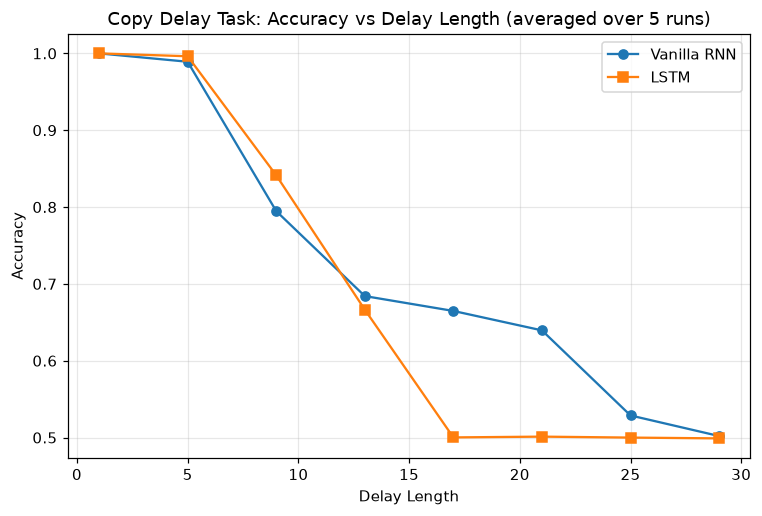

retardo,1,5,9,13,17,21,25,29
RNN,1.0,0.989,0.795,0.684,0.665,0.640,0.529,0.502
LSTM,1.0,0.996,0.841,0.666,0.500,0.501,0.500,0.499


In [4]:
def binary_accuracy(output, target):
    preds = (torch.sigmoid(output) > 0.5).float()
    return (preds == target).float().mean().item()

def train_for_delay_early_stopping(model, delay):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    best_val_loss, epochs_no_improve, best_model_state = float('inf'), 0, None
    for epoch in range(max_epochs):
        model.train()
        for _ in range(100):
            seq_in, seq_target, _ = generate_batch_delay(batch_size, delay, input_size)
            optimizer.zero_grad()
            loss = criterion(model(seq_in)[:, delay:, :], seq_target[:, delay:, :])
            loss.backward()
            optimizer.step()
        model.eval(); val_loss = 0.0
        with torch.no_grad():
            for _ in range(20):
                seq_in, seq_target, _ = generate_batch_delay(batch_size, delay, input_size)
                val_loss += criterion(model(seq_in)[:, delay:, :], seq_target[:, delay:, :]).item()
        val_loss /= 20
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict()        # ⚠️ referencia, no copia (ver 2.3)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                break
    if best_model_state:
        model.load_state_dict(best_model_state)
    return model

def evaluate_for_delay(model, delay, trials=20):
    model.eval(); acc = 0
    with torch.no_grad():
        for _ in range(trials):
            seq_in, seq_target, _ = generate_batch_delay(batch_size, delay, input_size)
            acc += binary_accuracy(model(seq_in)[:, delay:, :], seq_target[:, delay:, :])
    return acc / trials

torch.manual_seed(0)
inicio = time.time()
rnn_accuracies, lstm_accuracies = [], []
for delay in delays:
    rnn_accs, lstm_accs = [], []
    for _ in range(num_runs):
        rnn = train_for_delay_early_stopping(VanillaRNN(input_size, hidden_size, output_size).to(device), delay)
        rnn_accs.append(evaluate_for_delay(rnn, delay))
        lstm = train_for_delay_early_stopping(LSTMModel(input_size, hidden_size, output_size).to(device), delay)
        lstm_accs.append(evaluate_for_delay(lstm, delay))
    rnn_accuracies.append(np.mean(rnn_accs)); lstm_accuracies.append(np.mean(lstm_accs))
print(f'Código original: {time.time() - inicio:.0f} s')

plt.figure(figsize=(8, 5))
plt.plot(delays, rnn_accuracies, 'o-', label='Vanilla RNN')
plt.plot(delays, lstm_accuracies, 's-', label='LSTM')
plt.xlabel('Delay Length'); plt.ylabel('Accuracy')
plt.title(f'Copy Delay Task: Accuracy vs Delay Length (averaged over {num_runs} runs)')
plt.legend(); plt.grid(True); plt.show()
tabla_original = pd.DataFrame({'RNN': rnn_accuracies, 'LSTM': lstm_accuracies}, index=pd.Index(delays, name='retardo'))
display(tabla_original.T)

**Resultado: se reproduce lo que anuncia el enunciado.**

* Con retardos cortos los dos modelos aciertan casi todo (d = 1 y 5: 99–100 %), y con d = 9 la LSTM va algo por delante (84,1 % frente a 79,5 %).
* A partir de d = 13 la **LSTM es peor**: empatan con d = 13 (66,6 % frente a 68,4 %), y desde d = 17 la LSTM se queda **exactamente en el 50 %**, el azar: no ha aprendido nada.
* La RNN todavía retiene algo con d = 17 y 21 (66,5 % y 64,0 %) y cae al azar con d = 29 (50,2 %).

Es justo lo contrario de lo que dice la teoría (la LSTM debería recordar más lejos). Las 80 redes se entrenan en 258 s: cada una recibe como mucho 1 500 lotes. La sección 2 busca la causa en las curvas de aprendizaje.

# 2. Diagnóstico: las curvas de aprendizaje

## 2.1. Una función de entrenamiento instrumentada

`entrenar()` hace lo mismo que el código original pero **guarda las curvas** (pérdida de entrenamiento y de validación y exactitud de validación por época) y permite cambiar cada pieza:

* `max_epocas`, `paciencia` (`None` = sin parada temprana), `h`, `lr`, `bs`, `clip` (recorte del gradiente);
* `sesgo_olvido`: valor inicial del sesgo de la puerta de olvido de la LSTM (PyTorch lo inicializa aleatorio cerca de 0);
* `ortogonal`: inicializa la matriz recurrente $\mathbf W_{hh}$ de la RNN como **matriz ortogonal** (teoría del Lab 2);
* `copiar_estado`: `False` reproduce el error del original al guardar el mejor modelo (2.3);
* `parar_si_resuelto`: deja de entrenar si la pérdida de validación baja de 0,001 (la red ya acierta todos los bits; solo ahorra tiempo).

La **evaluación** usa siempre las **mismas 640 secuencias de test** para cada retardo (un generador con semilla fija), las mismas para los dos modelos. Devuelve también la exactitud en **cada posición** de la segunda mitad.

In [5]:
class ModeloCopia(nn.Module):
    def __init__(self, tipo, h, sesgo_olvido=None, ortogonal=False):
        super().__init__()
        self.rnn = getattr(nn, tipo)(5, h, batch_first=True)
        self.fc = nn.Linear(h, 5)
        if ortogonal and tipo == 'RNN':
            nn.init.orthogonal_(self.rnn.weight_hh_l0)
        if sesgo_olvido is not None and tipo == 'LSTM':
            for nombre, p in self.rnn.named_parameters():
                if 'bias' in nombre:                         # orden de PyTorch: entrada, olvido, celda, salida
                    p.data[h:2 * h] = sesgo_olvido / 2      # bias_ih + bias_hh = sesgo_olvido
    def forward(self, x):
        return self.fc(self.rnn(x)[0])


def lote(bs, d, gen=None):
    x = torch.zeros(bs, 2 * d, 5)
    x[:, :d] = (torch.rand(bs, d, 5, generator=gen) > 0.5).float()
    y = torch.zeros_like(x); y[:, d:] = x[:, :d]
    return x, y


def evaluar(modelo, d, n_lotes=20, bs=32):
    disp = next(modelo.parameters()).device
    gen = torch.Generator().manual_seed(1000 + d)               # mismas secuencias de test para todos
    modelo.eval(); aciertos = torch.zeros(d)
    with torch.no_grad():
        for _ in range(n_lotes):
            x, y = lote(bs, d, gen)
            pred = (modelo(x.to(disp))[:, d:] > 0).float().cpu()
            aciertos += (pred == y[:, d:]).float().mean(dim=(0, 2))
    return (aciertos / n_lotes).mean().item(), (aciertos / n_lotes).numpy()


def entrenar(tipo, d, h=32, lr=0.01, max_epocas=15, paciencia=3, bs=32, pasos=100, clip=None, sesgo_olvido=None,
             ortogonal=False, copiar_estado=True, parar_si_resuelto=True, semilla=0):
    disp = DISPOSITIVO[tipo]
    torch.manual_seed(semilla)
    modelo = ModeloCopia(tipo, h, sesgo_olvido, ortogonal).to(disp)
    opt = optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.BCEWithLogitsLoss()
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    mejor, estado, sin_mejora, inicio = np.inf, None, 0, time.time()
    for epoca in range(max_epocas):
        modelo.train(); suma = 0.0
        for _ in range(pasos):
            x, y = lote(bs, d)
            loss = criterio(modelo(x.to(disp))[:, d:], y[:, d:].to(disp))
            opt.zero_grad(); loss.backward()
            if clip:
                nn.utils.clip_grad_norm_(modelo.parameters(), clip)
            opt.step(); suma += loss.item()
        modelo.eval(); vl = va = 0.0
        with torch.no_grad():
            for _ in range(20):
                x, y = lote(bs, d)
                o = modelo(x.to(disp))[:, d:].cpu()
                vl += criterio(o, y[:, d:]).item() / 20
                va += ((o > 0).float() == y[:, d:]).float().mean().item() / 20
        hist['train_loss'].append(suma / pasos); hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if vl < mejor:
            mejor, sin_mejora = vl, 0
            estado = copy.deepcopy(modelo.state_dict()) if copiar_estado else modelo.state_dict()
        else:
            sin_mejora += 1
            if paciencia is not None and sin_mejora >= paciencia:
                break
        if parar_si_resuelto and vl < 1e-3:
            break
    modelo.load_state_dict(estado)
    acc, por_pos = evaluar(modelo, d)
    return modelo, {'hist': hist, 'epocas': len(hist['val_loss']), 'mejor_epoca': int(np.argmin(hist['val_loss'])) + 1,
                    'test_acc': acc, 'acc_posicion': por_pos, 'segundos': time.time() - inicio,
                    'parametros': sum(p.numel() for p in modelo.parameters())}

## 2.2. Curvas con los parámetros por defecto

Para ver qué pasa **más allá** del punto en que la parada temprana corta, se entrena con los parámetros por defecto pero **60 épocas sin parada temprana**, y se marca con una línea discontinua la época en que la paciencia 3 habría parado (3 semillas por retardo).

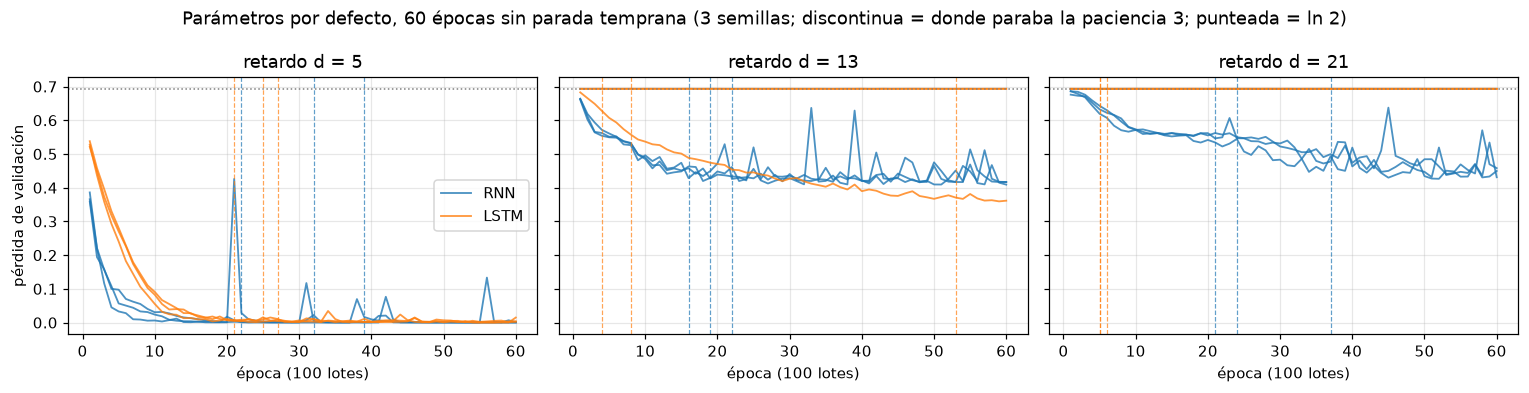

parada (paciencia 3)  exactitud val. en esa época  \
modelo retardo                                                      
LSTM   5                      24.333                        0.998   
       13                     21.667                        0.601   
       21                      5.333                        0.501   
RNN    5                      31.000                        0.997   
       13                     19.000                        0.698   
       21                     27.333                        0.651   

                exactitud val. tras 60 épocas  
modelo retardo                                 
LSTM   5                                0.998  
       13                               0.599  
       21                               0.500  
RNN    5                                1.000  
       13                               0.709  
       21                               0.688

In [6]:
def epoca_parada(vl, paciencia=3):
    mejor, sin = np.inf, 0
    for e, v in enumerate(vl, 1):
        if v < mejor:
            mejor, sin = v, 0
        else:
            sin += 1
            if sin >= paciencia:
                return e
    return len(vl)

RETARDOS_DIAG = (5, 13, 21)
curvas_def = {(t, d, s): entrenar(t, d, max_epocas=60, paciencia=None, parar_si_resuelto=False, semilla=s)[1]
              for t in ('RNN', 'LSTM') for d in RETARDOS_DIAG for s in range(3)}

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for k, d in enumerate(RETARDOS_DIAG):
    for t, color in (('RNN', 'tab:blue'), ('LSTM', 'tab:orange')):
        for s in range(3):
            vl = curvas_def[(t, d, s)]['hist']['val_loss']
            ax[k].plot(range(1, 61), vl, color=color, alpha=0.8, lw=1.2, label=t if s == 0 else None)
            ax[k].axvline(epoca_parada(vl), color=color, ls='--', lw=0.8, alpha=0.7)
    ax[k].axhline(np.log(2), color='gray', ls=':', lw=1); ax[k].set_title(f'retardo d = {d}'); ax[k].set_xlabel('época (100 lotes)')
ax[0].set_ylabel('pérdida de validación'); ax[0].legend()
plt.suptitle('Parámetros por defecto, 60 épocas sin parada temprana (3 semillas; discontinua = donde paraba la paciencia 3; punteada = ln 2)')
plt.tight_layout(); plt.show()

diag = pd.DataFrame([{'modelo': t, 'retardo': d, 'semilla': s, 'parada (paciencia 3)': epoca_parada(i['hist']['val_loss']),
                      'exactitud val. en esa época': i['hist']['val_acc'][epoca_parada(i['hist']['val_loss']) - 1],
                      'exactitud val. tras 60 épocas': i['hist']['val_acc'][-1]}
                     for (t, d, s), i in curvas_def.items()])
display(diag.groupby(['modelo', 'retardo']).mean(numeric_only=True).drop(columns='semilla'))

**Lo que dicen las curvas** (la línea punteada es $\ln 2$, la pérdida de no saber nada):

* **d = 5**: los dos modelos aprenden enseguida. La RNN tiene **picos** (la pérdida salta a 0,43 en una época y vuelve a bajar), señal de que la tasa 0,01 es alta para ella.
* **d = 13**: la RNN aprende desde la primera época, pero se estanca hacia 0,42 con muchos picos. De las 3 LSTM, **2 se quedan completamente planas en $\ln 2$ las 60 épocas**. La tercera despega y acaba **por debajo de la RNN** (≈ 0,36): cuando la LSTM aprende, aprende mejor.
* **d = 21**: las 3 LSTM se quedan planas en $\ln 2$ todo el tiempo. La RNN baja poco a poco hasta ≈ 0,45.
* **La parada temprana** corta a la LSTM en las épocas 4–8 (en plena meseta) con d = 13 y 21. Pero eso no es lo principal: aunque se deje entrenar 60 épocas, la LSTM sigue en el 60 % (d = 13) y el 50 % (d = 21) de media. **El problema no es solo cuánto se entrena, sino que la LSTM no recibe ninguna señal útil** para empezar a recordar.

## 2.3. Un error al guardar el mejor modelo

`best_model_state = model.state_dict()` **no copia** los pesos: devuelve un diccionario con **referencias** a los mismos tensores del modelo. Cuando el optimizador sigue actualizando el modelo, el «mejor estado» cambia con él. Al final, `load_state_dict(best_model_state)` carga… **los pesos de la última época**, no los de la mejor. Hay que guardar una copia (`copy.deepcopy`).

In [7]:
m = VanillaRNN(5, 4, 5); opt_demo = optim.Adam(m.parameters(), lr=0.1)
guardado = m.state_dict()                          # lo que hace el original
copia = copy.deepcopy(m.state_dict())              # lo correcto
x, y, _ = generate_batch_delay(8, 3, 5)
loss = nn.BCEWithLogitsLoss()(m(x), y); loss.backward(); opt_demo.step()
print('¿el "mejor estado" del original sigue igual tras un paso?',
      torch.equal(guardado['fc.weight'], copia['fc.weight']), '-> ha cambiado con el modelo')
print('¿el estado guardado ES el modelo actual?', guardado['fc.weight'].data_ptr() == m.fc.weight.data_ptr())

¿el "mejor estado" del original sigue igual tras un paso? False -> ha cambiado con el modelo
¿el estado guardado ES el modelo actual? True


## 2.4. Resumen del diagnóstico

1. **La LSTM se queda atascada en la meseta inicial** (pérdida $\ln 2$, 50 %): con retardos de 13 o más, la mayoría de las ejecuciones no despegan ni con 60 épocas. Es coherente con la teoría: con el sesgo de la puerta de olvido cerca de 0, la puerta empieza en $\sigma(0)=0{,}5$ y la información (y el gradiente) se divide por 2 en cada paso. Cuando la LSTM sí despega, supera a la RNN.
2. **La parada temprana con paciencia 3** corta a la LSTM durante esa meseta, y **15 épocas** son poco presupuesto para los dos modelos.
3. **La RNN aprende algo desde el principio**, pero se estanca y tiene picos de inestabilidad con tasa 0,01.
4. **Un error** al guardar el mejor modelo (2.3).
5. **Capacidad**: con 32 unidades hay que guardar $5d$ bits (85 con d = 17, 145 con d = 29).

La sección 3 ataca cada punto por separado.

# 3. Experimentos

**Metodología.** Cada opción se prueba con los **dos modelos**, en dos retardos representativos, **17** (dependencia media, 85 bits) y **29** (el más difícil del original, 145 bits), con **3 semillas**, y se mide la exactitud en test (las mismas secuencias para todos). El proceso es acumulativo: lo que mejora pasa al experimento siguiente.

Los resultados en esta tarea son muy **bimodales**: una red o «despega» de la meseta del 50 % o se queda en ella. Por eso se mira la media y también cuántas de las 3 ejecuciones superan el 90 %.

In [8]:
RETARDOS_EXP = (17, 29)
_cache = {}

def entrenar_cache(tipo, d, semilla, **cambios):
    # cada experimento repite la configuración ganadora del anterior: se reutiliza en lugar de reentrenar
    clave = (tipo, d, semilla, tuple(sorted(cambios.items())))
    if clave not in _cache:
        _cache[clave] = entrenar(tipo, d, semilla=semilla, **cambios)[1]
    return _cache[clave]

def probar(nombre, variantes):
    # variantes: {etiqueta: {'RNN': cambios, 'LSTM': cambios}}, con los cambios = parámetros de entrenar()
    filas = []
    for etiqueta, por_modelo in variantes.items():
        for tipo, cambios in por_modelo.items():
            for d in RETARDOS_EXP:
                res = [entrenar_cache(tipo, d, s, **cambios) for s in range(3)]
                accs = [r['test_acc'] for r in res]
                filas.append({nombre: etiqueta, 'modelo': tipo, 'retardo': d, 'exactitud': np.mean(accs),
                              'mín': np.min(accs), '≥ 90 %': f"{sum(a >= 0.9 for a in accs)}/3",
                              'épocas': np.mean([r['epocas'] for r in res]),
                              's/entrenamiento': np.mean([r['segundos'] for r in res])})
    df = pd.DataFrame(filas)
    display(df.pivot_table(index=[nombre, 'modelo'], columns='retardo', values='exactitud', sort=False)
              .style.format('{:.1%}').background_gradient(cmap='RdYlGn', vmin=0.5, vmax=1))
    return df

**Experimento 1: presupuesto de entrenamiento.** El original entrena como mucho 15 épocas y para tras 3 sin mejorar. Se compara con un presupuesto amplio: hasta **100 épocas** (10 000 lotes) con **paciencia 20**, con el error del estado corregido en los dos casos.

In [9]:
exp1 = probar('presupuesto', {
    '15 épocas, paciencia 3 (original)': {'RNN': {}, 'LSTM': {}},
    '100 épocas, paciencia 20': {'RNN': dict(max_epocas=100, paciencia=20), 'LSTM': dict(max_epocas=100, paciencia=20)},
})

**Experimento 1.** Más presupuesto ayuda algo a la RNN (d = 17: 67,5 % → 70,1 %; d = 29: 52,0 % → 56,6 %) y **nada a la LSTM**, que sigue en el 50 % en los dos retardos aun con hasta 10 000 lotes. Confirma el diagnóstico: el problema de la LSTM no es el tiempo de entrenamiento. Se mantiene el presupuesto amplio (100 épocas, paciencia 20) para lo que sigue.

**Experimento 2: tamaño del estado oculto.** Con 32 unidades hay que guardar 85 o 145 bits; se prueba con 128.

In [10]:
P = dict(max_epocas=100, paciencia=20)
exp2 = probar('unidades ocultas', {
    'h = 32': {'RNN': P | dict(h=32), 'LSTM': P | dict(h=32)},
    'h = 128': {'RNN': P | dict(h=128), 'LSTM': P | dict(h=128)},
})

**Experimento 2.** Con la inicialización por defecto y tasa 0,01, pasar a 128 unidades **empeora** a la RNN (d = 17: 70,1 % → 53,1 %) y apenas cambia la LSTM (50,2 % → 53,5 %). Más unidades no sirven si la señal no llega a través del tiempo.

Aun así se mantiene **h = 128** en lo que sigue. Es una decisión de diseño, no una conclusión de este experimento: con 32 unidades no caben los 145 bits de d = 29. Los experimentos 3 y 4 muestran que, con la inicialización y la tasa adecuadas, los modelos de 128 unidades sí aprovechan esa capacidad (93–97 % con d = 29, muy por encima de cualquier resultado con 32).

**Experimento 3: una inicialización que conserve la memoria.** Es el experimento clave, y se hace para los dos modelos:

* **LSTM — sesgo de la puerta de olvido.** PyTorch lo inicializa cerca de 0, así que la puerta empieza en $\sigma(0)=0{,}5$: en cada paso se olvida la mitad del contenido de la celda, y la señal (y el gradiente) que tiene que cruzar $d$ pasos se multiplica por $0{,}5^{d}$: $0{,}5^{17}\approx8\cdot10^{-6}$. Con sesgo $b_f$, la puerta empieza en $\sigma(b_f)$: $0{,}73$ con 1 y $0{,}95$ con 3 ($0{,}95^{17}\approx0{,}42$). La red empieza **recordando** y aprende cuándo olvidar.
* **RNN — $\mathbf W_{hh}$ ortogonal.** Con la inicialización por defecto, el radio espectral de $\mathbf W_{hh}$ es $\approx1/\sqrt3\approx0{,}58$ y la señal también se atenúa exponencialmente. Una matriz ortogonal **conserva la norma** al multiplicar paso a paso (teoría del Lab 2) y, además, una permutación (un caso de matriz ortogonal) es justo una línea de retardo.

In [11]:
P = dict(max_epocas=100, paciencia=20, h=128)
exp3 = probar('inicialización', {
    'por defecto': {'RNN': P, 'LSTM': P},
    'LSTM sesgo de olvido 1': {'LSTM': P | dict(sesgo_olvido=1.0)},
    'LSTM sesgo de olvido 3 · RNN W_hh ortogonal': {'RNN': P | dict(ortogonal=True), 'LSTM': P | dict(sesgo_olvido=3.0)},
})

**Experimento 3: el cambio decisivo para la LSTM.**

* Con **sesgo de olvido 1**, la LSTM pasa del 53,5 % al **96,6 %** con d = 17 (55,4 % con d = 29).
* Con **sesgo de olvido 3**, llega al **100 %** con d = 17 y al **80,2 %** con d = 29. Por primera vez supera con claridad a la RNN.
* La **RNN con $\mathbf W_{hh}$ ortogonal** mejora con d = 17 (53,1 % → 73,2 %) pero, con tasa 0,01, sigue en el azar con d = 29.

Es exactamente lo que predice la teoría: si la puerta de olvido empieza cerca de 1, la celda conserva la información y el gradiente llega a través de los 17 o 29 pasos desde la primera época, y la red aprende cuándo olvidar.

**Experimento 4: tasa de aprendizaje y recorte del gradiente.** Con la mejor inicialización de cada modelo, Adam con 0,01 (el original), 0,003 y 0,001 con recorte del gradiente a norma 1.

In [12]:
P_RNN = dict(max_epocas=100, paciencia=20, h=128, ortogonal=True)
P_LSTM = dict(max_epocas=100, paciencia=20, h=128, sesgo_olvido=3.0)
exp4 = probar('tasa', {
    'lr 0,01': {'RNN': P_RNN | dict(lr=0.01), 'LSTM': P_LSTM | dict(lr=0.01)},
    'lr 0,003': {'RNN': P_RNN | dict(lr=0.003), 'LSTM': P_LSTM | dict(lr=0.003)},
    'lr 0,001 + recorte 1': {'RNN': P_RNN | dict(lr=0.001, clip=1.0), 'LSTM': P_LSTM | dict(lr=0.001, clip=1.0)},
})

**Experimento 4.**

* La **RNN** necesitaba una tasa menor: con 0,003 llega al **100 %** (d = 17) y al **94,2 %** (d = 29), y con 0,001 y recorte, al **100 % y 97,3 %**. Con $\mathbf W_{hh}$ ortogonal y pasos pequeños, la RNN conserva la señal 29 pasos. Tiene sentido: una línea de retardo es exactamente una **permutación**, y una permutación es una matriz ortogonal. Esta tarea es muy natural para una RNN bien inicializada.
* La **LSTM** también mejora con 0,003 (99,9 % y 92,9 %). Con 0,001 y recorte empeora (87,5 % y 76,6 %): con pasos tan pequeños no le da tiempo a despegar en 100 épocas.
* **Configuraciones finales**, ambas con 128 unidades y el mismo presupuesto:
  * RNN: $\mathbf W_{hh}$ ortogonal, tasa 0,001 y recorte 1;
  * LSTM: sesgo de olvido 3 y tasa 0,003.

In [13]:
def mejor_de(df, modelo):
    t = df[df['modelo'] == modelo].groupby('tasa', sort=False)['exactitud'].mean()
    return t.idxmax()

LR_OPCIONES = {'lr 0,01': dict(lr=0.01), 'lr 0,003': dict(lr=0.003), 'lr 0,001 + recorte 1': dict(lr=0.001, clip=1.0)}
CFG_RNN = P_RNN | LR_OPCIONES[mejor_de(exp4, 'RNN')]
CFG_LSTM = P_LSTM | LR_OPCIONES[mejor_de(exp4, 'LSTM')]
print('RNN :', CFG_RNN); print('LSTM:', CFG_LSTM)

RNN : {'max_epocas': 100, 'paciencia': 20, 'h': 128, 'ortogonal': True, 'lr': 0.001, 'clip': 1.0}
LSTM: {'max_epocas': 100, 'paciencia': 20, 'h': 128, 'sesgo_olvido': 3.0, 'lr': 0.003}


# 4. Comparación justa

Condiciones iguales para los dos modelos: **mismo presupuesto** (hasta 100 épocas de 100 lotes, paciencia 20), **mismas secuencias de test**, 5 ejecuciones por retardo, retardos 1–29 (los del original) y, para ver hasta dónde llega cada uno, 37 y 45. Cada modelo usa **su mejor configuración**, y además se añade una **RNN con el mismo número de parámetros** que la LSTM (h = 256 frente a 128: ≈ 70 000 parámetros cada una), para que la diferencia no se deba a que la LSTM es más grande.

In [14]:
CONFIG = {'RNN (h = 128)': ('RNN', CFG_RNN), 'LSTM (h = 128)': ('LSTM', CFG_LSTM),
          'RNN (h = 256, mismos parámetros)': ('RNN', CFG_RNN | dict(h=256))}
RETARDOS_FINAL = list(range(1, 30, 4)) + [37, 45]
final, modelos_29 = {}, {}
inicio = time.time()
for nombre, (tipo, cfg) in CONFIG.items():
    for d in RETARDOS_FINAL:
        res = []
        for s in range(5):
            m, info = entrenar(tipo, d, semilla=s, **cfg)
            res.append(info)
            if d == 29 and s == 0:
                modelos_29[nombre] = info
        final[(nombre, d)] = res
    print(f'{nombre}: {time.time() - inicio:.0f} s acumulados | parámetros {res[0]["parametros"]}')

tabla_final = pd.DataFrame({nombre: [np.mean([r['test_acc'] for r in final[(nombre, d)]]) for d in RETARDOS_FINAL]
                            for nombre in CONFIG}, index=pd.Index(RETARDOS_FINAL, name='retardo'))
display(tabla_final.T.style.format('{:.1%}').background_gradient(cmap='RdYlGn', vmin=0.5, vmax=1, axis=None))

RNN (h = 128): 2160 s acumulados | parámetros 17925


LSTM (h = 128): 8280 s acumulados | parámetros 69765


RNN (h = 256, mismos parámetros): 9150 s acumulados | parámetros 68613


retardo,1,5,9,13,17,21,25,29,37,45
RNN (h = 128),100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,99.8%,97.1%,87.1%,80.6%
LSTM (h = 128),100.0%,100.0%,100.0%,100.0%,99.9%,98.9%,95.9%,92.6%,80.4%,77.1%
"RNN (h = 256, mismos parámetros)",100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,99.7%


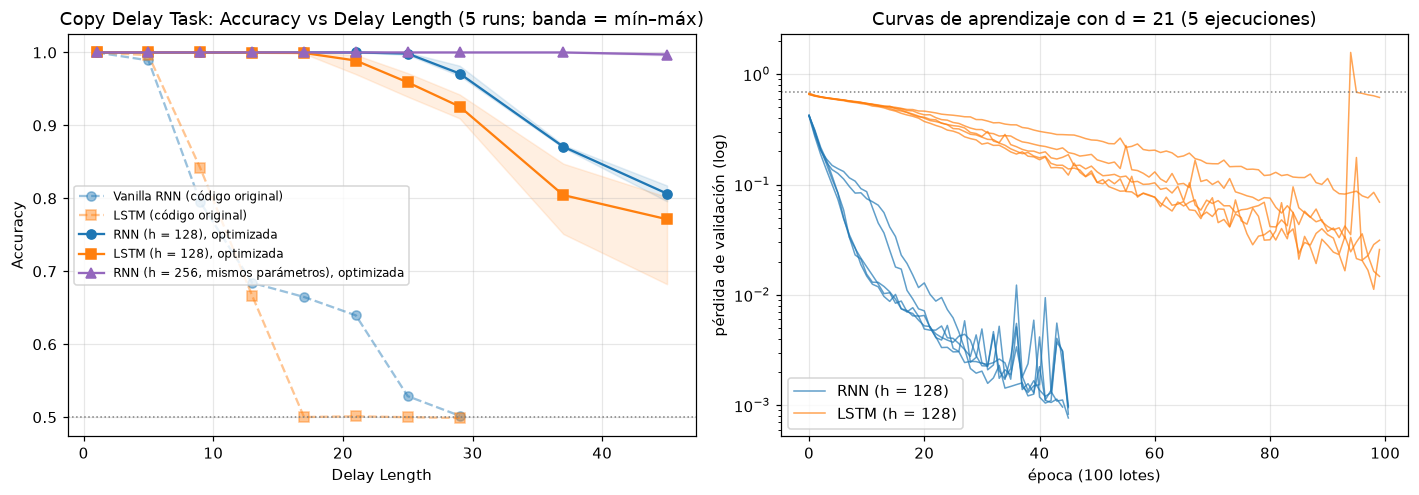

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].plot(delays, rnn_accuracies, 'o--', color='tab:blue', alpha=0.45, label='Vanilla RNN (código original)')
ax[0].plot(delays, lstm_accuracies, 's--', color='tab:orange', alpha=0.45, label='LSTM (código original)')
estilos = {'RNN (h = 128)': ('o-', 'tab:blue'), 'LSTM (h = 128)': ('s-', 'tab:orange'),
           'RNN (h = 256, mismos parámetros)': ('^-', 'tab:purple')}
for nombre in CONFIG:
    accs = np.array([[r['test_acc'] for r in final[(nombre, d)]] for d in RETARDOS_FINAL])
    m_, c_ = estilos[nombre]
    ax[0].plot(RETARDOS_FINAL, accs.mean(1), m_, color=c_, label=f'{nombre}, optimizada')
    ax[0].fill_between(RETARDOS_FINAL, accs.min(1), accs.max(1), color=c_, alpha=0.12)
ax[0].axhline(0.5, color='gray', ls=':', lw=1)
ax[0].set_xlabel('Delay Length'); ax[0].set_ylabel('Accuracy')
ax[0].set_title('Copy Delay Task: Accuracy vs Delay Length (5 runs; banda = mín–máx)'); ax[0].legend(fontsize=8)

for nombre in ('RNN (h = 128)', 'LSTM (h = 128)'):
    for s, r in enumerate(final[(nombre, 21)]):
        ax[1].plot(r['hist']['val_loss'], color=estilos[nombre][1], alpha=0.7, lw=1, label=nombre if s == 0 else None)
ax[1].axhline(np.log(2), color='gray', ls=':', lw=1)
ax[1].set_yscale('log'); ax[1].set_xlabel('época (100 lotes)'); ax[1].set_ylabel('pérdida de validación (log)')
ax[1].set_title('Curvas de aprendizaje con d = 21 (5 ejecuciones)'); ax[1].legend()
plt.tight_layout(); plt.show()

**Comparación justa** (exactitud media de 5 ejecuciones; entre paréntesis, la peor):

| Retardo | 17 | 21 | 25 | 29 | 37 | 45 |
|---|---|---|---|---|---|---|
| RNN original (h = 32) | 66,5 % | 64,0 % | 52,9 % | 50,2 % | — | — |
| LSTM original (h = 32) | 50,0 % | 50,1 % | 50,0 % | 49,9 % | — | — |
| **RNN** (h = 128, $\mathbf W_{hh}$ ortogonal; 17 925 parámetros) | 100 % | 100 % | 99,8 % | 97,1 % | 87,1 % | 80,6 % |
| **LSTM** (h = 128, sesgo de olvido 3; 69 765) | 99,9 % | 98,9 % (97,0) | 95,9 % (93,9) | 92,6 % (91,0) | 80,4 % (75,1) | 77,1 % (68,2) |
| **RNN** (h = 256, mismos parámetros que la LSTM; 68 613) | 100 % | 100 % | 100 % | **100 %** | **100 %** | **99,7 %** |

* **Las dos redes optimizadas mejoran enormemente** a las originales: con d = 29 pasan del 50 % al 93–97 %. Los objetivos del enunciado se cumplen de sobra.
* **Pero la comparación justa no la gana la LSTM.** Con el mismo número de unidades, la RNN ortogonal es mejor en todos los retardos largos y mucho más estable entre semillas. Con el mismo número de **parámetros** (RNN de 256), la RNN es prácticamente perfecta hasta d = 45.
* **La RNN aprende mucho más deprisa** (derecha, d = 21): llega a una pérdida de 0,001 en unas 40 épocas, mientras que la LSTM sigue bajando poco a poco al final de las 100 épocas, y una de sus ejecuciones tiene un pico de inestabilidad hacia la época 93. Con más presupuesto la LSTM probablemente mejoraría, pero con el mismo presupuesto pierde.
* **La caída de la RNN coincide con su capacidad.** Una línea de retardo exacta necesita guardar $5d$ números a la vez. La RNN de 128 unidades es perfecta hasta d = 25 (125 ≤ 128) y cae a partir de ahí (145, 185 y 225 bits). La de 256 aguanta hasta d = 45 (225 ≤ 256). Es lo esperable si la red ha aprendido una matriz parecida a una **permutación que desplaza** el contenido del estado oculto cada paso.

# 5. ¿Qué posiciones recuerda cada modelo?

Exactitud de cada una de las 29 posiciones de la segunda mitad con $d = 29$ (primera ejecución de cada configuración final). La posición $k$ de la salida reproduce el vector de entrada del paso $k$.

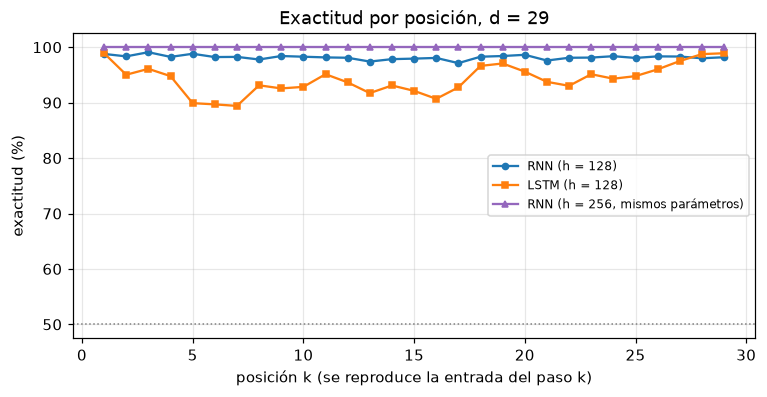

In [16]:
plt.figure(figsize=(8, 3.6))
for nombre, info in modelos_29.items():
    plt.plot(range(1, 30), 100 * info['acc_posicion'], estilos[nombre][0], ms=4, color=estilos[nombre][1], label=nombre)
plt.axhline(50, color='gray', ls=':', lw=1)
plt.xlabel('posición k (se reproduce la entrada del paso k)'); plt.ylabel('exactitud (%)')
plt.title('Exactitud por posición, d = 29'); plt.legend(fontsize=8); plt.show()

* La **RNN** recuerda **todas las posiciones por igual** (≈ 98 % con h = 128 y 100 % con h = 256): se comporta como un registro de desplazamiento, donde cada vector recorre el estado oculto paso a paso.
* La **LSTM** tiene forma de **U**: recuerda mejor los primeros vectores (≈ 99 % en la posición 1) y los últimos (≈ 99 % en la 27–29) que los del medio (≈ 90 % entre la 5 y la 16). La LSTM no guarda una cola ordenada sino que «escribe» cada vector en celdas de memoria; los del principio tienen celdas libres para ellos y los del final se recuerdan durante menos tiempo. Es el mismo efecto de primacía y recencia de la memoria humana.

# 6. Conclusiones

1. **Qué hace el código.** La tarea de copia con retardo pide reproducir en la segunda mitad la secuencia de bits aleatorios de la primera. El error es la entropía cruzada binaria **solo en la segunda mitad**, y el azar es el 50 % (pérdida $\ln 2$). Tiene sentido porque **aísla la memoria**, controla con un solo parámetro la **distancia** que tiene que recorrer el gradiente y mide la **capacidad** ($5d$ bits).
2. **Por qué la LSTM salía peor.** Las curvas de aprendizaje muestran que la LSTM por defecto **se queda plana en la meseta** de $\ln 2$: su puerta de olvido empieza en 0,5, y la señal y el gradiente se dividen por 2 en cada paso. La paciencia 3 la cortaba en la meseta, pero ni con 60 épocas despegaba. Además, el código tenía un error al guardar el mejor modelo.
3. **Optimización.**
   * Lo decisivo es una **inicialización que conserve la memoria**: el sesgo de olvido 3 en la LSTM (del 50 % al 100 % con d = 17) y $\mathbf W_{hh}$ ortogonal en la RNN.
   * Después, la **tasa**: 0,003 para la LSTM y 0,001 con recorte para la RNN.
   * También más **presupuesto** y **capacidad** (128 unidades).
4. **Comparación justa** (mismo presupuesto, mismas secuencias, cada modelo con su mejor configuración):
   * las dos resuelven retardos que el código original no podía (con d = 29, 93–97 % frente al 50 %);
   * en **esta** tarea gana la RNN ortogonal: aprende más rápido, es más estable y, con los mismos parámetros, es casi perfecta hasta d = 45;
   * la LSTM recuerda mejor los extremos de la secuencia que el centro.
5. **Interpretación.** La tarea es una **línea de retardo fija**, y una permutación (que es una matriz ortogonal) la resuelve exactamente: es el caso ideal para una RNN con $\mathbf W_{hh}$ ortogonal, y su límite es la capacidad ($5d$ ≤ h). La ventaja de la LSTM está en otra cosa: **decidir qué guardar y cuándo olvidar**. Brilla en tareas con información relevante dispersa entre mucho ruido, o donde el retardo no es fijo, y además no depende de una inicialización delicada (bastó con el sesgo de olvido). Con los parámetros por defecto, en cambio, la LSTM ni siquiera empezaba a aprender: **la comparación entre arquitecturas solo es justa si cada una recibe su inicialización y su tasa adecuadas**.

In [17]:
def a_lista(df):
    return [{k: (v if isinstance(v, str) else float(v)) for k, v in fila.items()} for fila in df.to_dict('records')]

resultados = {
    'original': {'delays': delays, 'rnn': rnn_accuracies, 'lstm': lstm_accuracies},
    'diagnostico': a_lista(diag.groupby(['modelo', 'retardo']).mean(numeric_only=True).drop(columns='semilla').reset_index()),
    'experimentos': {'presupuesto': a_lista(exp1), 'unidades': a_lista(exp2), 'inicializacion': a_lista(exp3), 'tasa': a_lista(exp4)},
    'config': {'RNN': CFG_RNN, 'LSTM': CFG_LSTM},
    'final': {nombre: {str(d): [r['test_acc'] for r in final[(nombre, d)]] for d in RETARDOS_FINAL} for nombre in CONFIG},
    'parametros': {nombre: final[(nombre, 1)][0]['parametros'] for nombre in CONFIG},
    'posicion_29': {nombre: info['acc_posicion'].tolist() for nombre, info in modelos_29.items()},
}
with open(LAB_DIR / 'resultados_lab3_copia.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1, default=float)
print('Resultados guardados en resultados_lab3_copia.json')

Resultados guardados en resultados_lab3_copia.json
